<a href="https://colab.research.google.com/github/manishamali14/E-Commerce-Sales-Analysis/blob/main/Manisha_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Sales Analysis
## Step 1: Data Exploration

Importing libraries and downloading the dataset.

In [188]:
import gdown
import pandas as pd
import matplotlib.pyplot as plt
gdown.download("https://drive.google.com/uc?id=1pwVsvM0ZwXK20JWSGXN6rlgUjePnCrsZ", "sales_dataset.csv", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1pwVsvM0ZwXK20JWSGXN6rlgUjePnCrsZ
To: /content/sales_dataset.csv
100%|██████████| 67.9M/67.9M [00:00<00:00, 175MB/s]


'sales_dataset.csv'

Loading the data and viewing the first rows.

In [189]:
df = pd.read_csv("sales_dataset.csv", low_memory=False)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (128949, 23)


,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Order ID            128949 non-null  object 
 1   Date                128949 non-null  object 
 2   Status              128949 non-null  object 
 3   Fulfilment          128949 non-null  object 
 4   Sales Channel       128949 non-null  object 
 5   ship-service-level  128949 non-null  object 
 6   Style               128949 non-null  object 
 7   SKU                 128949 non-null  object 
 8   Category            128949 non-null  object 
 9   Size                128949 non-null  object 
 10  ASIN                128949 non-null  object 
 11  Courier Status      122078 non-null  object 
 12  Qty                 128949 non-null  int64  
 13  currency            121155 non-null  object 
 14  Amount              121155 non-null  float64
 15  ship-city           128916 non-nul

In [191]:
# missing values in each column
df.isnull().sum()

,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0
Size,0


Checking duplicate rows and unique orders.

In [192]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique orders:", df["Order ID"].nunique())

Duplicate rows: 6
Unique orders: 120352


**Observations**
* 128,949 rows and 23 columns.
* Amount has 7,794 missing values.
* 6 duplicate rows found.
* "Unnamed: 22" column is empty.
* Date is stored as text.

## Step 2: Data Cleaning


### 2.1 Removing empty column and duplicates

Removing the empty column, cleaning column names and dropping duplicates.

In [193]:
df = df.drop(columns=["Unnamed: 22"])

# lowercase names, no spaces
df.columns = df.columns.str.strip().str.lower()
df.columns = df.columns.str.replace(" ", "_").str.replace("-", "_")

df = df.drop_duplicates()
print(df.shape)

(128943, 22)


### 2.2 Handling missing values


Filling missing Amount with the median.

In [194]:
median_amount = df["amount"].median()
print("Median amount:", median_amount)

df["amount"] = df["amount"].fillna(median_amount)

Median amount: 605.0


Filling other missing values with suitable labels.

In [195]:
# all orders are in INR
df["currency"] = df["currency"].fillna("INR")

df["courier_status"] = df["courier_status"].fillna("Unknown")

# fulfilled_by is blank only for orders fulfilled by Amazon
print(pd.crosstab(df["fulfilment"], df["fulfilled_by"].isnull()))
df["fulfilled_by"] = df["fulfilled_by"].fillna("Amazon")

# blank promotion means no promotion was used
df["promotion_ids"] = df["promotion_ids"].fillna("No Promotion")

df["ship_city"] = df["ship_city"].fillna("Unknown")
df["ship_state"] = df["ship_state"].fillna("Unknown")
df["ship_country"] = df["ship_country"].fillna("IN")

df.isnull().sum()

fulfilled_by  False  True 
fulfilment                
Amazon            0  89673
Merchant      39270      0


,0
order_id,0
date,0
status,0
fulfilment,0
sales_channel,0
ship_service_level,0
style,0
sku,0
category,0
size,0


### 2.3 Fixing data types



Converting date to datetime and postal code to integer.

In [196]:
# date has two formats in the file, so using mixed
df["date"] = pd.to_datetime(df["date"], format="mixed")
print(df["date"].min(), "to", df["date"].max())

df["ship_postal_code"] = df["ship_postal_code"].astype("Int64")
df.dtypes

2022-03-31 00:00:00 to 2022-06-29 00:00:00


,0
order_id,object
date,datetime64[ns]
status,object
fulfilment,object
sales_channel,object
ship_service_level,object
style,object
sku,object
category,object
size,object


### 2.4 Standardising text

Fixing state spellings and short forms.

In [197]:
print("States before:", df["ship_state"].nunique())

df["ship_state"] = df["ship_state"].str.strip().str.upper()

state_map = {
    "AR": "ARUNACHAL PRADESH",
    "NL": "NAGALAND",
    "PB": "PUNJAB",
    "RJ": "RAJASTHAN",
    "RAJSHTHAN": "RAJASTHAN",
    "RAJSTHAN": "RAJASTHAN",
    "ORISSA": "ODISHA",
    "PONDICHERRY": "PUDUCHERRY",
    "NEW DELHI": "DELHI",
    "PUNJAB/MOHALI/ZIRAKPUR": "PUNJAB",
    "DADRA AND NAGAR": "DADRA AND NAGAR HAVELI",
}
df["ship_state"] = df["ship_state"].replace(state_map)

print("States after:", df["ship_state"].nunique())

States before: 70
States after: 38


Cleaning city names and category text.

In [198]:
print("Cities before:", df["ship_city"].nunique())
df["ship_city"] = df["ship_city"].str.strip().str.upper().str.rstrip(".,")
print("Cities after:", df["ship_city"].nunique())

df["category"] = df["category"].str.strip().str.title()
df["category"].value_counts()

Cities before: 8956
Cities after: 7254


,count
category,
Set,50272
Kurta,49864
Western Dress,15495
Top,10621
Ethnic Dress,1158
Blouse,926
Bottom,440
Saree,164
Dupatta,3


### 2.5 New columns

Adding month and customer type columns.

In [199]:
df["month"] = df["date"].dt.month_name()
df["customer_type"] = df["b2b"].map({True: "B2B", False: "B2C"})

df[["date", "month", "b2b", "customer_type"]].head()

,date,month,b2b,customer_type
0,2022-04-30,April,False,B2C
1,2022-04-30,April,False,B2C
2,2022-04-30,April,True,B2B
3,2022-04-30,April,False,B2C
4,2022-04-30,April,False,B2C


### 2.6 Checking outliers

Finding outliers in Amount using the IQR method.

Outliers in amount: 4177


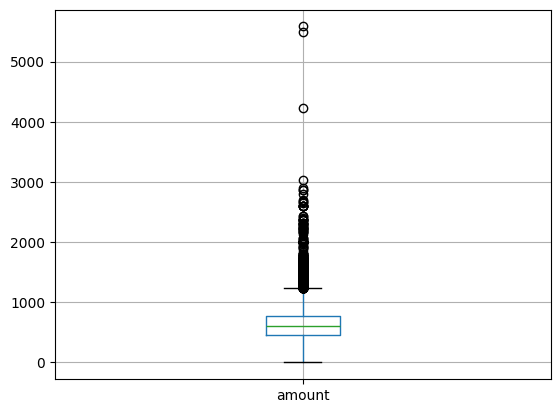

In [200]:
q1 = df["amount"].quantile(0.25)
q3 = df["amount"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print("Outliers in amount:", (df["amount"] > upper).sum())

df.boxplot(column="amount")
plt.show()

**Observations**
* 4,177 rows have amount above ₹1,239, mostly Set orders.
* These are real orders, not errors, so they are kept.

In [201]:
print("Final shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
df.isnull().sum()

Final shape: (128943, 24)
Duplicates: 0


,0
order_id,0
date,0
status,0
fulfilment,0
sales_channel,0
ship_service_level,0
style,0
sku,0
category,0
size,0


Saving the cleaned data.

In [202]:
df.to_csv("sales_dataset_cleaned.csv", index=False)

**Cleaning Summary**
* Removed 6 duplicates and 1 empty column.
* Filled Amount nulls with median (605).
* Fixed date format and state names (70 to 38).
* Final data: 128,943 rows.

## Step 3: Analysis
### 3.1 Financial Performance


Calculating total sales, net revenue and average order value.

In [203]:
# cancelled orders did not bring any money
sold = df[df["status"] != "Cancelled"]

print("Total sales (all orders):", round(df["amount"].sum(), 2))
print("Net revenue (without cancelled):", round(sold["amount"].sum(), 2))
print("Total orders:", df["order_id"].nunique())
print("Average order value:", round(sold["amount"].sum() / sold["order_id"].nunique(), 2))
print("Average amount per item:", round(df["amount"].mean(), 2))

Total sales (all orders): 83286092.94
Net revenue (without cancelled): 71786173.62
Total orders: 120352
Average order value: 695.89
Average amount per item: 645.91


Monthly revenue trend.

month
March       95415.00
April    26284149.62
May      23986391.00
June     21420218.00
Name: amount, dtype: float64


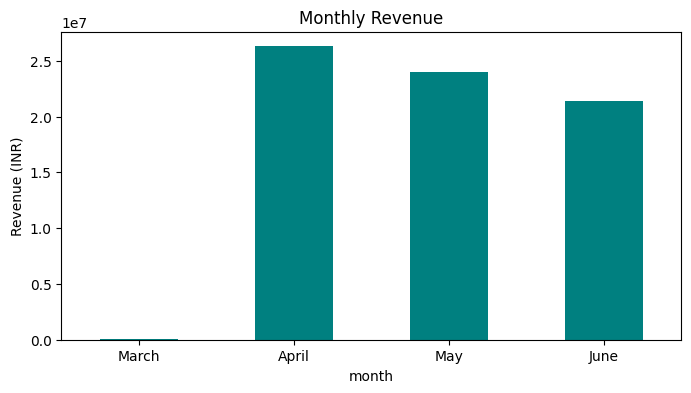

In [204]:
month_order = ["March", "April", "May", "June"]
monthly = sold.groupby("month")["amount"].sum().reindex(month_order)
print(monthly)

monthly.plot(kind="bar", figsize=(8, 4), color="teal")
plt.title("Monthly Revenue")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.show()

Weekly revenue trend.

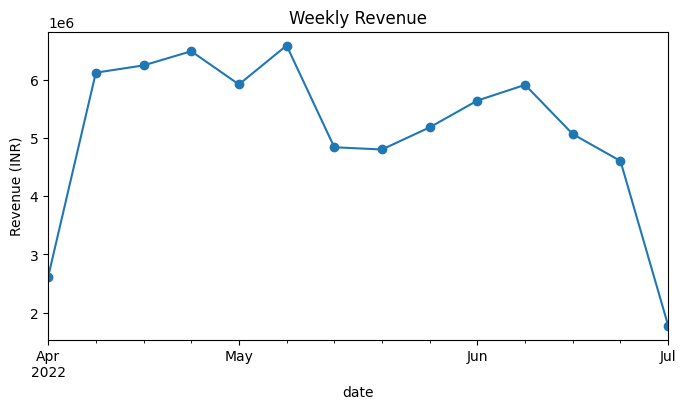

In [205]:
# weekly trend to see ups and downs
weekly = sold.set_index("date")["amount"].resample("W").sum()

weekly.plot(figsize=(8, 4), marker="o")
plt.title("Weekly Revenue")
plt.ylabel("Revenue (INR)")
plt.show()

Revenue by category.

category
Set              35783725.14
Kurta            19479334.48
Western Dress    10208945.00
Top               4909572.00
Ethnic Dress       732121.00
Blouse             420809.00
Bottom             136058.00
Saree              114694.00
Dupatta               915.00
Name: amount, dtype: float64


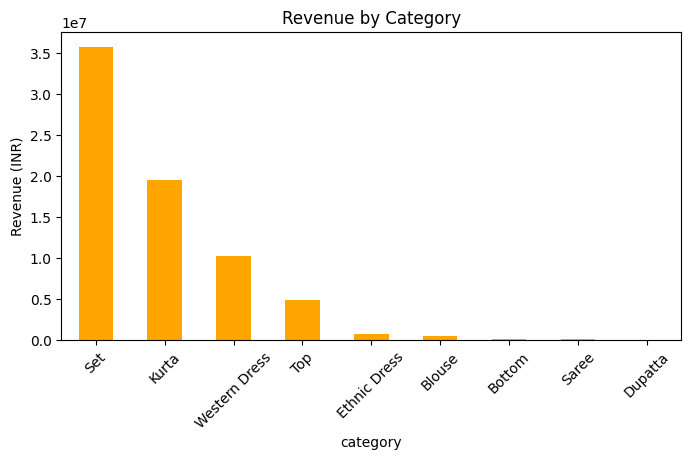

In [206]:
cat_sales = sold.groupby("category")["amount"].sum().sort_values(ascending=False)
print(cat_sales)

cat_sales.plot(kind="bar", figsize=(8, 4), color="orange")
plt.title("Revenue by Category")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.show()

Top selling products.

In [207]:
# top selling products
print(sold.groupby("sku")["qty"].sum().sort_values(ascending=False).head(10))
print(sold.groupby("style")["amount"].sum().sort_values(ascending=False).head(10))

sku
JNE3797-KR-L      646
JNE3797-KR-M      555
JNE3797-KR-S      489
JNE3405-KR-L      452
J0230-SKD-M       434
JNE3797-KR-XL     408
J0230-SKD-S       401
JNE3405-KR-S      380
JNE3797-KR-XS     371
JNE3797-KR-XXL    352
Name: qty, dtype: int64
style
JNE3797    2637913.0
J0230      1793265.0
SET268     1192006.0
J0341      1153249.0
J0003       880378.0
JNE3405     774231.0
J0008       754804.0
SET345      668876.0
SET278      658473.0
SET324      651227.0
Name: amount, dtype: float64


**Observations**
* Net revenue is ₹7.18 crore and AOV is ₹695.89.
* April had the highest sales, then sales dropped.
* Set and Kurta are the top categories.
* Style JNE3797 is the best selling product.
* Data covers only 31 March to June, so full seasonal trends cannot be seen.
* Monthly revenue: April ₹2.63 crore, May ₹2.40 crore, June ₹2.14 crore.

### 3.2 Customer Insights

Top 10 states by revenue.

ship_state
MAHARASHTRA       12234616.00
KARNATAKA          9648629.00
TELANGANA          6294073.57
UTTAR PRADESH      6184815.00
TAMIL NADU         5959537.00
DELHI              4052099.48
KERALA             3378842.00
WEST BENGAL        3208355.00
ANDHRA PRADESH     2887107.00
HARYANA            2655292.00
Name: amount, dtype: float64


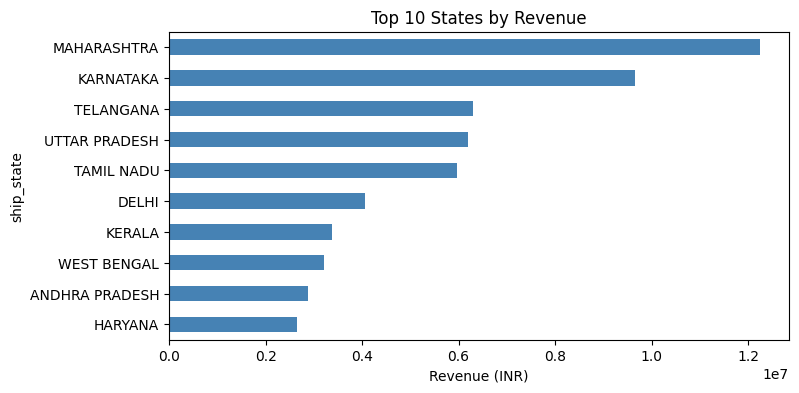

In [208]:
top_states = sold.groupby("ship_state")["amount"].sum().sort_values(ascending=False).head(10)
print(top_states)

top_states.sort_values().plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue (INR)")
plt.show()

Top 10 cities by revenue.

In [209]:
sold.groupby("ship_city")["amount"].sum().sort_values(ascending=False).head(10)

,amount
ship_city,
BENGALURU,6727972.00
HYDERABAD,5089151.57
MUMBAI,3960192.00
NEW DELHI,3636033.48
CHENNAI,3300813.00
PUNE,2581313.00
KOLKATA,1548376.00
GURUGRAM,1191505.00
THANE,1016338.00


Cancellation rate by month and category.

In [210]:
df["is_cancelled"] = df["status"] == "Cancelled"

print("Cancellation rate:", round(df["is_cancelled"].mean() * 100, 2), "%")
print((df.groupby("month")["is_cancelled"].mean() * 100).reindex(month_order).round(2))
print((df.groupby("category")["is_cancelled"].mean() * 100).sort_values(ascending=False).round(2))

Cancellation rate: 14.22 %
month
March    10.53
April    14.55
May      13.99
June     14.07
Name: is_cancelled, dtype: float64
category
Set              14.59
Kurta            14.55
Western Dress    13.71
Bottom           13.64
Saree            12.80
Ethnic Dress     12.61
Blouse           12.53
Top              12.01
Dupatta           0.00
Name: is_cancelled, dtype: float64


Comparing B2B and B2C customers.

In [211]:
print(sold.groupby("customer_type")["order_id"].nunique())
print(sold.groupby("customer_type")["amount"].sum())
print(sold.groupby("customer_type")["amount"].mean())

customer_type
B2B       728
B2C    102430
Name: order_id, dtype: int64
customer_type
B2B      560005.00
B2C    71226168.62
Name: amount, dtype: float64
customer_type
B2B    701.760652
B2C    648.648707
Name: amount, dtype: float64


**Observations**
* Maharashtra and Karnataka bring the most revenue.
* 14.22% of orders are cancelled.
* B2C makes up almost all orders.
* No customer ID, so retention cannot be measured.
* Bengaluru is the top city by revenue.
* B2B has only 728 orders compared to 1,02,430 for B2C.

### 3.3 Logistics and Fulfilment

Comparing Amazon and Merchant fulfilment.

In [212]:
print(df["fulfilment"].value_counts())
print(sold.groupby("fulfilment")["amount"].sum())
print(df.groupby("fulfilment")["is_cancelled"].mean() * 100)

fulfilment
Amazon      89673
Merchant    39270
Name: count, dtype: int64
fulfilment
Amazon      50703370.00
Merchant    21082803.62
Name: amount, dtype: float64
fulfilment
Amazon      12.797609
Merchant    17.473899
Name: is_cancelled, dtype: float64


Shipping service level and cancellations.

In [213]:
print(pd.crosstab(df["fulfilment"], df["ship_service_level"]))
print((df.groupby("ship_service_level")["is_cancelled"].mean() * 100).round(2))

ship_service_level  Expedited  Standard
fulfilment                             
Amazon                  88590      1083
Merchant                    0     39270
ship_service_level
Expedited    12.90
Standard     17.12
Name: is_cancelled, dtype: float64


**Observations**
* Amazon fulfils 70% of orders.
* Merchant orders are cancelled more (17.5% vs 12.8%).
* No delivery date, so shipping time cannot be calculated.
* 939 orders are still pending, which shows delays in processing.
* Standard shipping orders are cancelled more than Expedited (17.1% vs 12.9%).

### 3.4 Product and Inventory

Orders and average quantity by category.

In [214]:
print(df["category"].value_counts())
print(sold.groupby("category")["qty"].mean().round(2))
print("Average quantity per order:", round(sold["qty"].mean(), 2))

category
Set              50272
Kurta            49864
Western Dress    15495
Top              10621
Ethnic Dress      1158
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Name: count, dtype: int64
category
Blouse           1.03
Bottom           1.01
Dupatta          1.00
Ethnic Dress     1.00
Kurta            1.00
Saree            1.03
Set              1.00
Top              1.00
Western Dress    1.00
Name: qty, dtype: float64
Average quantity per order: 1.0


Units sold by size.

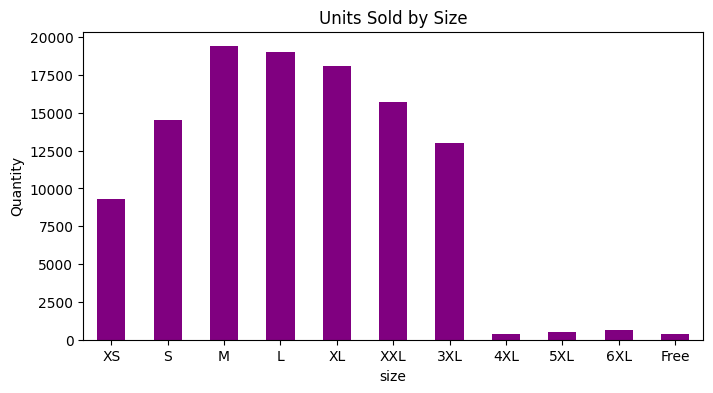

In [215]:
size_order = ["XS", "S", "M", "L", "XL", "XXL", "3XL", "4XL", "5XL", "6XL", "Free"]
size_qty = sold.groupby("size")["qty"].sum().reindex(size_order)

size_qty.plot(kind="bar", figsize=(8, 4), color="purple")
plt.title("Units Sold by Size")
plt.ylabel("Quantity")
plt.xticks(rotation=0)
plt.show()

**Observations**
* Set and Kurta are in highest demand.
* Most orders have 1 item.
* M and L sizes sell the most.

### 3.5 Returns

Return rate by category.

In [216]:
df["is_returned"] = df["status"].str.contains("Returned|Returning|Rejected")

print("Returned orders:", df["is_returned"].sum())
print("Return rate:", round(df["is_returned"].mean() * 100, 2), "%")
print((df.groupby("category")["is_returned"].mean() * 100).sort_values(ascending=False).round(2))

Returned orders: 2109
Return rate: 1.64 %
category
Western Dress    2.21
Set              1.68
Kurta            1.51
Ethnic Dress     1.38
Bottom           1.36
Blouse           1.30
Top              1.26
Saree            0.61
Dupatta          0.00
Name: is_returned, dtype: float64


Order status breakdown.

status
Shipped                          77764
Shipped - Delivered to Buyer     28771
Cancelled                        18338
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64


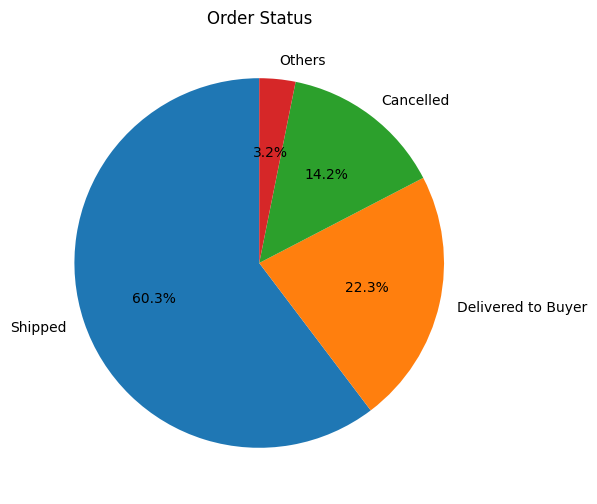

In [217]:
status_counts = df["status"].value_counts()
print(status_counts)

# small statuses grouped together so labels don't overlap
top = status_counts.head(3).copy()
top["Others"] = status_counts.iloc[3:].sum()
top.index = top.index.str.replace("Shipped - ", "")

top.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6), startangle=90)
plt.title("Order Status")
plt.ylabel("")
plt.show()

**Observations**
* Return rate is 1.64%.
* Western Dress has the highest return rate (2.21%).
* Cancellations are a bigger issue than returns.
* 2,109 orders were returned or rejected.

## Recommendations
* Focus stock and marketing on Set and Kurta.
* Reduce Merchant order cancellations.
* Target top states like Maharashtra and Karnataka.
* Stock more M, L and XL sizes.
* Improve Western Dress quality to cut returns.
* Speed up Merchant order processing to reduce pending and cancelled orders.
* Add clear size charts and an easy return policy to improve customer experience.

## Conclusion
Most revenue comes from Set and Kurta and from B2C buyers. Reducing the 14% cancellation rate is the biggest opportunity.